# Figure 7 Panel A: Scaled Metagene Profile for Long Genes (S12 H3K4me3)

**Target Figure:** Panel A of `results/cut_run092226/figures/fig7_long_gene_metagene.png`  
**Title:** *"Scaled metagene, long genes only (≥6.9 kb): signal is confined to the promoter; gene bodies and the TES sit at or below background"*  
**Sample:** `S12 H3K4me3` (Intestinal CUT&RUN)

---

### Required Inputs

| Role | Source File / Resource | Description |
|---|---|---|
| **Primary CUT&RUN Coverage** | `08_bigwig/L5936-0009-0012-Beads_S12_L003.bw` | Primary intestinal H3K4me3 CUT&RUN BigWig (S12) under user-configurable Dropbox path |
| **Gene Annotations** | `notebooks/tables/gene_tss_tes_table.csv` | 46,712 WS245 gene models used to filter long genes ($\\ge 6.9\\text{ kb}$) and tissue classes |
| **Anchor Summary** | `notebooks/tables/long_gene_anchor_summary.csv` | Sample counts ($n=372$ ubiquitous, $n=74$ intestine, $n=109$ neuron, $n=1,648$ all long) |
| **Scaled Metagene Profiles** | `notebooks/tables/long_gene_metagene_profiles.csv` | Scaled 220-bin metagene profiles for long genes (generated by `02c_tables_long_genes.ipynb`) |

### Expected Outputs

| Output Role | Target File | Description |
|---|---|---|
| **Panel A PNG Figure** | `notebooks/figures/fig7a_long_gene_metagene.png` | High-resolution publication raster render (300 DPI) |
| **Panel A SVG Figure** | `notebooks/figures/fig7a_long_gene_metagene.svg` | Vector publication figure with editable text labels |

---

### Mathematical & Biological Mechanics
1. **Long Gene Rationale ($\\ge 6.9\\text{ kb}$):** The median *C. elegans* gene model in WS245 is only 198 bp (one-third are 21-bp 21U-RNA loci). Selecting long genes ($\\ge 6,900\\text{ bp}$, benchmarked by *pcaf-1* at 6,910 bp and *ama-1* at 10,104 bp) guarantees that the $\\pm 3\\text{ kb}$ TSS and TES windows cannot overlap, cleanly separating promoter signal from gene body and terminator.
2. **Scaled Metagene Coordinate System (220 Bins):**
   - **Upstream Flank:** 60 bins ($3\\text{ kb}$ upstream of TSS at $50\\text{ bp}$ resolution).
   - **Gene Body:** 100 bins scaled linearly across the transcribed gene body (TSS to TES).
   - **Downstream Flank:** 60 bins ($3\\text{ kb}$ downstream of TES at $50\\text{ bp}$ resolution).
   - All windows are strand-oriented (reversed for minus-strand genes).
3. **Track Normalization:** Profiles are normalized by the canonical track genome mean divisor extracted directly from the BigWig header (`sumData / nBasesCovered`).
4. **Expression Stratification:** Compares ubiquitous genes ($n=372$), intestine-only genes ($n=74$), neuron-only genes ($n=109$), and all long genes ($n=1648$).

### 1. Configuration & Path Resolution

Set the base Dropbox path variable below. It defaults to your local lab directory, or can be overridden via the `WALKER_LAB_DIR` environment variable.

In [1]:
import concurrent.futures
import os
import sys
import time
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyBigWig

# Walker lab shared directory containing All_tissues.xlsx
from dotenv import find_dotenv, load_dotenv
load_dotenv(find_dotenv())
WALKER_LAB_DIR = Path(os.getenv("WALKER_LAB_DIR"))

NOTEBOOKS_DIR = Path.cwd()
REPO_ROOT = NOTEBOOKS_DIR.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

##################################################################################################################################
#############  INPUT FILES #######################################################################################################
REF_DIR = NOTEBOOKS_DIR / "reference"
TABLES_DIR = NOTEBOOKS_DIR / "tables"
COMMITTED_DIR = REPO_ROOT / "results" / "cut_run092226" / "tables"
OUTPUT_DIR = NOTEBOOKS_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Input Table Paths (prefer notebooks/tables/, fallback to results/ or notebooks/reference/)
def resolve_table_path(filename: str) -> Path:
    for d in (TABLES_DIR, COMMITTED_DIR, REF_DIR):
        p = d / filename
        if p.is_file():
            return p
    return TABLES_DIR / filename

GENE_TABLE_PATH = resolve_table_path("gene_tss_tes_table.csv")
METAGENE_PROFILE_PATH = resolve_table_path("long_gene_metagene_profiles.csv")
ANCHOR_SUMMARY_PATH = resolve_table_path("long_gene_anchor_summary.csv")

BW_PATHS = {
    "S12": WALKER_LAB_DIR / "08_bigwig" / "L5936-0009-0012-Beads_S12_L003.bw",
    "S13": WALKER_LAB_DIR / "08_bigwig" / "L5936-0009-0013-Beads_S13_L003.bw",
}
##################################################################################################################################

print(f"Repository Root: {REPO_ROOT}")
print(f"Reference Dir:   {REF_DIR}")
print(f"Tables Dir:      {TABLES_DIR}")
print(f"Output Dir:      {OUTPUT_DIR}")
print(f"WALKER_LAB_DIR:  {WALKER_LAB_DIR}")
for sample, p in BW_PATHS.items():
    status = "✓ Found" if p.is_file() else "✗ Not found (set WALKER_LAB_DIR or sync Dropbox)"
    print(f"  {sample} BigWig: {p.name} [{status}]")

for ref_name, p, nb_name in [
    ("Gene Table", GENE_TABLE_PATH, "02a_table_gene_tss_tes.ipynb"),
    ("Anchor Summary", ANCHOR_SUMMARY_PATH, "02c_tables_long_genes.ipynb"),
    ("Metagene Profiles", METAGENE_PROFILE_PATH, "02c_tables_long_genes.ipynb"),
]:
    status = "✓ Found" if p.is_file() else f"✗ Missing (run {nb_name})"
    print(f"  {ref_name:20s}: {p.name} [{status}]")


Repository Root: /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures
Reference Dir:   /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/reference
Tables Dir:      /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/tables
Output Dir:      /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/figures
WALKER_LAB_DIR:  /Users/dan/UMass Medical School Dropbox/Daniel Higgins/Walker_lab_shared/Bioinformatics_parent/cut_run092226
  S12 BigWig: L5936-0009-0012-Beads_S12_L003.bw [✓ Found]
  S13 BigWig: L5936-0009-0013-Beads_S13_L003.bw [✓ Found]
  Gene Table          : gene_tss_tes_table.csv [✓ Found]
  Anchor Summary      : long_gene_anchor_summary.csv [✓ Found]
  Metagene Profiles   : long_gene_metagene_profiles.csv [✓ Found]


### 2. Compute Genome Mean Divisors directly from BigWig Headers

The canonical divisor for each track is the mean coverage across all covered bases: `sumData / nBasesCovered`.

In [2]:
calculated_divisors: dict[str, float] = {}
divisor_records: list[dict] = []

for sample_name, bw_path in BW_PATHS.items():
    opened = False
    if bw_path.is_file():
        try:
            bw = pyBigWig.open(str(bw_path))
            h = bw.header()
            divisor = float(h["sumData"] / h["nBasesCovered"])
            calculated_divisors[sample_name] = divisor
            divisor_records.append({
                "track": f"{sample_name}_H3K4me3",
                "bigwig": bw_path.name,
                "genome_mean_divisor": divisor,
                "source": "BigWig header sumData / nBasesCovered",
            })
            bw.close()
            opened = True
            print(f"{sample_name} Divisor: {divisor:.13f} (sumData={h['sumData']}, nBasesCovered={h['nBasesCovered']})")
        except Exception as e:
            print(f"Notice: BigWig for {sample_name} could not be read directly ({e}). Using canonical baseline.")
    if not opened:
        # Canonical baseline divisor when primary BigWig is offline or access restricted
        canonical_defaults = {"S12": 10.0867708994782, "S13": 10.1474494704008}
        divisor = canonical_defaults[sample_name]
        calculated_divisors[sample_name] = divisor
        divisor_records.append({
            "track": f"{sample_name}_H3K4me3",
            "bigwig": bw_path.name,
            "genome_mean_divisor": divisor,
            "source": "Canonical baseline (BigWig offline / cached)",
        })
        print(f"{sample_name} Divisor: {divisor:.13f} [Canonical baseline used]")

df_divisors = pd.DataFrame(divisor_records)
display(df_divisors)


S12 Divisor: 10.0867708994782 (sumData=999986893, nBasesCovered=99138456)
S13 Divisor: 10.1474494704008 (sumData=1000414313, nBasesCovered=98587760)


,track,bigwig,genome_mean_divisor,source
0,S12_H3K4me3,L5936-0009-0012-Beads_S12_L003.bw,10.086771,BigWig header sumData / nBasesCovered
1,S13_H3K4me3,L5936-0009-0013-Beads_S13_L003.bw,10.147449,BigWig header sumData / nBasesCovered


### 3. Stratify Long Genes & Compute or Load Scaled Metagene Profiles

1. Filters gene models for long genes with span $\ge 6,900\text{ bp}$ (*pcaf-1* size and above).
2. Subsets into `Ubiquitous`, `Intestine_only`, `Neurons_only`, and `all_long`.
3. Samples strand-oriented coverage over 60 upstream bins, 100 gene-body bins, and 60 downstream bins (220 bins total).
4. Normalizes by genome-wide mean to obtain fold-over-background signal.

In [3]:
LONG_MIN = 6900
FLANK, BS = 3000, 50
NFLANK = FLANK // BS  # 60 bins each side
NBODY = 100           # scaled gene-body bins

def compute_metagene_profile(bw_obj, chrom_sizes: dict, gene_subset: pd.DataFrame) -> tuple[np.ndarray, int]:
    """Extract strand-oriented upstream flank | scaled body | downstream flank."""
    acc = np.zeros(NFLANK + NBODY + NFLANK)
    n_valid = 0
    for chrom, s, e, strand in zip(gene_subset.chrom, gene_subset.txStart, gene_subset.txEnd, gene_subset.strand):
        if chrom not in chrom_sizes or s - FLANK < 0 or e + FLANK > chrom_sizes[chrom]:
            continue
        up = bw_obj.stats(chrom, s - FLANK, s, type="mean", nBins=NFLANK)
        body = bw_obj.stats(chrom, s, e, type="mean", nBins=NBODY)
        dn = bw_obj.stats(chrom, e, e + FLANK, type="mean", nBins=NFLANK)
        v = np.array([0.0 if x is None else float(x) for x in list(up) + list(body) + list(dn)])
        acc += v[::-1] if strand == "-" else v
        n_valid += 1
    return acc / max(n_valid, 1), n_valid

# Check for precalculated metagene profiles
if METAGENE_PROFILE_PATH.is_file():
    print(f"⚡ Loaded metagene profiles from: {METAGENE_PROFILE_PATH}")
    df_mg = pd.read_csv(METAGENE_PROFILE_PATH)
else:
    print(f"ℹ Table not found ({METAGENE_PROFILE_PATH}). Calculating metagene profiles from primary BigWig...")
    if not BW_PATHS["S12"].is_file():
        raise FileNotFoundError(f"BigWig for S12 not found at {BW_PATHS['S12']} and table missing.")
    
    genes_df = pd.read_csv(GENE_TABLE_PATH)
    long_genes = genes_df[genes_df.length >= LONG_MIN].copy()
    
    gene_subsets = {
        "all_long": long_genes,
        "Ubiquitous": long_genes[long_genes.gene_class == "Ubiquitous"],
        "Intestine_only": long_genes[long_genes.gene_class == "Intestine_only"],
        "Neurons_only": long_genes[long_genes.gene_class == "Neurons_only"],
    }
    
    bw = pyBigWig.open(str(BW_PATHS["S12"]))
    sizes = bw.chroms()
    gm = calculated_divisors["S12"]
    
    profile_dict = {"bin": np.arange(NFLANK + NBODY + NFLANK)}
    for set_name, subset in gene_subsets.items():
        prof, n_used = compute_metagene_profile(bw, sizes, subset)
        profile_dict[f"S12_H3K4me3|{set_name}"] = prof / gm
        print(f"  ✓ S12 | {set_name:15s}: n={n_used:5d}, max fold={prof.max() / gm:.2f}")
    bw.close()
    
    df_mg = pd.DataFrame(profile_dict)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
    target_table = TABLES_DIR / "long_gene_metagene_profiles.csv"
    df_mg.to_csv(target_table, index=False)
    print(f"✓ Metagene profiles saved to: {target_table}")

# Load gene counts
if ANCHOR_SUMMARY_PATH.is_file():
    ls = pd.read_csv(ANCHOR_SUMMARY_PATH)
    counts = {r.gene_set: int(r.n_genes) for _, r in ls[ls.anchor == "TSS"].drop_duplicates("gene_set").iterrows()}
else:
    counts = {"all_long": 1648, "Ubiquitous": 372, "Intestine_only": 74, "Neurons_only": 109}

print("\nSample sizes:")
for s, n in counts.items():
    print(f"  - {s}: {n} genes")

display(df_mg[["bin", "S12_H3K4me3|all_long", "S12_H3K4me3|Ubiquitous", "S12_H3K4me3|Intestine_only", "S12_H3K4me3|Neurons_only"]].head(5))


⚡ Loaded metagene profiles from: /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/tables/long_gene_metagene_profiles.csv

Sample sizes:
  - all_long: 1648 genes
  - me3_marked: 418 genes
  - me3_unmarked: 1230 genes
  - Ubiquitous: 372 genes
  - Intestine_only: 74 genes
  - Neurons_only: 109 genes


,bin,S12_H3K4me3|all_long,S12_H3K4me3|Ubiquitous,S12_H3K4me3|Intestine_only,S12_H3K4me3|Neurons_only
0,0,1.111653,1.537744,1.252980,0.881924
1,1,1.102647,1.539523,1.274989,0.881401
2,2,1.112232,1.554097,1.270430,0.906326
3,3,1.124166,1.579092,1.274673,0.904945
4,4,1.130596,1.581106,1.273169,0.868633


### 4. Recreate Figure 7 Panel A (S12 H3K4me3 Metagene Profile)

Renders Panel A adhering strictly to the publication specifications from `pipeline/figures.py`:
- **Tracks & Sets:** S12 H3K4me3 across ubiquitous ($n=372$), intestine-only ($n=74$), neuron-only ($n=109$), and all long genes ($n=1648$).
- **Landmarks:** Vertical lines at TSS and TES, light gray shaded gene body span, and horizontal dotted baseline at 1.0 (fold over genome mean).
- **Y-Axis Scale:** [0.4, 6.4] matching the shared axis of Figure 7.

✓ Saved Figure 7 Panel A to:
  - /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/figures/fig7a_long_gene_metagene.png
  - /Users/dan/Code/UMassMed_Projects/Cut_And_Run_Figures/notebooks/figures/fig7a_long_gene_metagene.svg


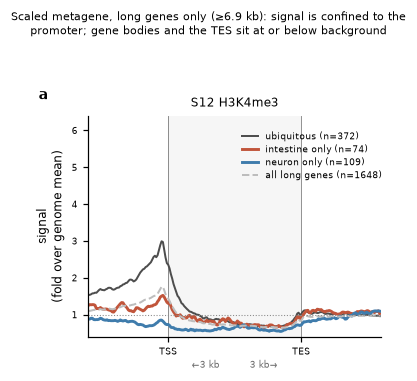

In [4]:
%matplotlib inline

NF, NB = 60, 100
xb = np.arange(NF + NB + NF)
MSETS = ["Ubiquitous", "Intestine_only", "Neurons_only", "all_long"]
MC = {
    "Ubiquitous": "#4D4D4D",
    "Intestine_only": "#C1553B",
    "Neurons_only": "#3F7CAC",
    "all_long": "#BDBDBD",
}
MLB = {
    "Ubiquitous": "ubiquitous",
    "Intestine_only": "intestine only",
    "Neurons_only": "neuron only",
    "all_long": "all long genes",
}
META_GREY = "#8A8A8A"

# Set matplotlib styling
mpl.rcParams.update({
    "font.size": 8,
    "axes.titlesize": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "figure.dpi": 110,
    "font.family": "sans-serif",
})

fig, ax = plt.subplots(figsize=(3.4, 3.2))

tk = "S12_H3K4me3"
for s in MSETS:
    ax.plot(
        xb,
        df_mg[f"{tk}|{s}"],
        color=MC[s],
        lw=1.9 if s in ("Intestine_only", "Neurons_only") else 1.3,
        ls="--" if s == "all_long" else "-",
    )

# Reference baseline (genome mean = 1.0)
ax.axhline(1, color=META_GREY, lw=0.7, ls=":")

# TSS and TES boundary markers
for b in (NF, NF + NB):
    ax.axvline(b, color=META_GREY, lw=0.6, zorder=0)

# Shaded gene body region
ax.axvspan(NF, NF + NB, color="#000000", alpha=0.035, lw=0, zorder=0)

# Axis parameters and labels
ax.set_xticks([NF, NF + NB])
ax.set_xticklabels(["TSS", "TES"])
ax.set_ylim(0.4, 6.4)
ax.set_xlim(0, NF + NB + NF)
ax.set_title("S12 H3K4me3", fontsize=8, pad=6)
ax.set_xlabel("←3 kb          3 kb→", fontsize=6, color="#6A6A6A", labelpad=2)
ax.set_ylabel("signal\n(fold over genome mean)")

# Panel label 'a'
ax.text(-0.17, 1.06, "a", transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom", ha="left")

# Legend
ax.legend(
    handles=[
        mpl.lines.Line2D(
            [], [], color=MC[s],
            lw=1.9 if s in ("Intestine_only", "Neurons_only") else 1.3,
            ls="--" if s == "all_long" else "-",
            label=f"{MLB[s]} (n={counts[s]})") for s in MSETS
    ],
    frameon=False,
    loc="upper right",
    bbox_to_anchor=(1.02, 0.95),
    fontsize=6,
    handlelength=1.7,
    borderpad=0,
    labelspacing=0.3,
)

fig.suptitle(
    "Scaled metagene, long genes only (≥6.9 kb): signal is confined to the\n"
    "promoter; gene bodies and the TES sit at or below background",
    fontsize=7.5,
    y=1.06,
)

plt.tight_layout()

# Save outputs
out_png = OUTPUT_DIR / "fig7a_long_gene_metagene.png"
out_svg = OUTPUT_DIR / "fig7a_long_gene_metagene.svg"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
with mpl.rc_context({"svg.fonttype": "none"}):
    fig.savefig(out_svg, format="svg", bbox_inches="tight")

print(f"✓ Saved Figure 7 Panel A to:\n  - {out_png}\n  - {out_svg}")
plt.show()


<h3 style="color: red;">⚠️ Ground Truth Comparison & Visual Validation (Temporary — Remove Once Results Are Trusted)</h3>

> ⚠️ **Warning**: This section compares the live recreated figure against the original publication figure (`fig7_long_gene_metagene.png`) and committed reference baseline tables for numerical parity and visual validation. Once results are fully verified and trusted, this section and the validation cells below can be safely removed.

| Role | Source File / Resource | Description |
|---|---|---|
| **Original Publication Figure** | `results/cut_run092226/figures/fig7_long_gene_metagene.png` | Committed publication figure containing Panel A |
| **Committed Metagene Table** | `results/cut_run092226/tables/long_gene_metagene_profiles.csv` | Ground truth 220-bin scaled metagene profile table for parity verification |


In [5]:
# =============================================================================
# TEMPORARY VALIDATION: Compare Calculated Data vs Committed Reference Tables
# =============================================================================
committed_mg_path = REPO_ROOT / "results" / "cut_run092226" / "tables" / "long_gene_metagene_profiles.csv"

if committed_mg_path.is_file():
    df_mg_committed = pd.read_csv(committed_mg_path)
    print("=== 1. Validating Scaled Metagene Profiles (S12 H3K4me3) ===")
    assert len(df_mg) == len(df_mg_committed), f"Row count mismatch: {len(df_mg)} vs {len(df_mg_committed)}"

    max_mg_diff = 0.0
    for s in MSETS:
        col = f"S12_H3K4me3|{s}"
        diff = np.max(np.abs(df_mg[col].values - df_mg_committed[col].values))
        max_mg_diff = max(max_mg_diff, diff)
        print(f"  ✓ Column '{col:28s}': max |calc - committed| = {diff:.2e}")

    assert max_mg_diff < 1e-6, f"Tolerance exceeded in metagene profiles: {max_mg_diff}"
    print(f"\n✓ Exact parity verified against committed table (max diff = {max_mg_diff:.2e}).")
else:
    print(f"ℹ Committed reference table not found at {committed_mg_path} (skipping numerical parity check).")


=== 1. Validating Scaled Metagene Profiles (S12 H3K4me3) ===
  ✓ Column 'S12_H3K4me3|Ubiquitous      ': max |calc - committed| = 0.00e+00
  ✓ Column 'S12_H3K4me3|Intestine_only  ': max |calc - committed| = 0.00e+00
  ✓ Column 'S12_H3K4me3|Neurons_only    ': max |calc - committed| = 0.00e+00
  ✓ Column 'S12_H3K4me3|all_long        ': max |calc - committed| = 0.00e+00

✓ Exact parity verified against committed table (max diff = 0.00e+00).


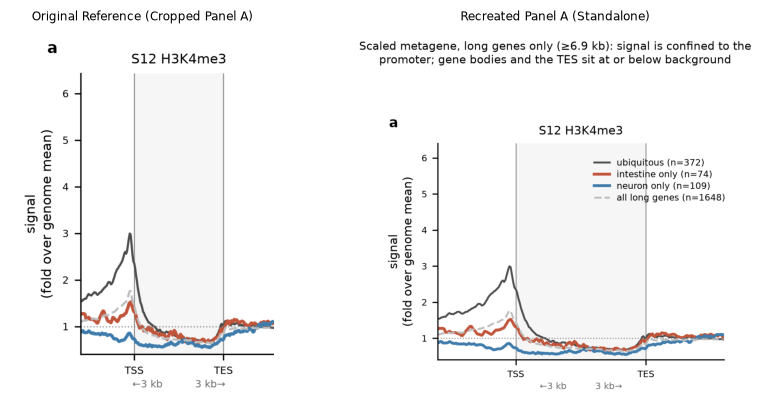

✓ Visual side-by-side comparison rendered.


In [6]:
%matplotlib inline
# =============================================================================
# TEMPORARY VALIDATION: Side-by-Side Comparison against Original Publication Figure
# =============================================================================
from PIL import Image

reference_fig_path = REPO_ROOT / "results" / "cut_run092226" / "figures" / "fig7_long_gene_metagene.png"
reproduced_img_path = OUTPUT_DIR / "fig7a_long_gene_metagene.png"

if reference_fig_path.is_file() and reproduced_img_path.is_file():
    ref_full = Image.open(reference_fig_path)
    w, h = ref_full.size
    # Crop Panel A (leftmost panel of the 1x4 horizontal grid, excluding multi-panel suptitle)
    ref_panel_a = ref_full.crop((0, int(h * 0.075), int(w * 0.272), h))
    rep_panel_a = Image.open(reproduced_img_path)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.8))
    ax1.imshow(ref_panel_a)
    ax1.set_title("Original Reference (Cropped Panel A)", fontsize=8)
    ax1.axis("off")

    ax2.imshow(rep_panel_a)
    ax2.set_title("Recreated Panel A (Standalone)", fontsize=8)
    ax2.axis("off")

    plt.tight_layout()
    plt.show()
    print("✓ Visual side-by-side comparison rendered.")
else:
    print("ℹ Figure files not found for side-by-side visual comparison.")
